# EnTransformer on Venezuela Dengue — Step 1 of 2: tuning one horizon with Optuna

This notebook tunes EnTransformer for **one** forecast horizon, set by `HORIZON` at the top of Part 1. Run **three copies in parallel**, one per horizon (`"short"`, `"medium"`, `"long"`). 
| Part | Contents |
|---|---|
| 0 | Installation, imports, versions |
| 1 | Configuration (**`HORIZON`**), search space |
| 1b | Forecast head check and (tunable) log transform |
| 2–4 | Data, `TimeSeries`, train / validation / test split + leakage checks |
| 6 | Shared helpers (model builder, package energy score check, forecasting, metrics) |
| 7 | **Optuna tuning for `HORIZON`** on the validation window |
| 8 | Save the study and the best settings |

Models are fitted on the training weeks and scored on the validation weeks only.

## Part 0a — Installation

* We use `darts` **0.47.0**: darts 0.48.x moved an internal class and `engressionts 0.1.1` fails to import with it.
* `pytorch-lightning` is required by Darts' torch models but is **not** pulled in by `engressionts` itself.
* `openpyxl` reads the `.xlsx` data file.
* Kaggle already ships `torch`; we do not reinstall it.


In [1]:
%%capture install_log
!pip install -q "darts==0.47.0" "engressionts==0.1.1" pytorch-lightning openpyxl optuna statsforecast

In [2]:
# Show only the tail of the install log (errors would appear here).
# Safe to run after a kernel restart: it just says the log is gone.
if "install_log" in globals():
    print(install_log.stdout[-1500:] or "install finished quietly")
    print(install_log.stderr[-1500:])
else:
    print("No install log in this kernel session (fine after a restart) - continue to Part 1.")

install finished quietly



## Part 0b - Imports and Versions 

Package versions are recorded here and saved at the end of the notebook.

In [3]:
import os, sys, json, time, platform, warnings, logging
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner, NopPruner
from optuna.trial import TrialState

import darts, pytorch_lightning as pl
from darts.models import AutoARIMA, AutoETS, NaiveSeasonal
from darts import TimeSeries
from darts.dataprocessing import Pipeline
from darts.dataprocessing.transformers import Scaler, InvertibleMapper
from sklearn.preprocessing import StandardScaler

import engressionts
import engressionts.base.base_engression as eng_base
from engressionts.models import EnTransformerModel
from engressionts import metrics as M          # mae, rmse, crps, empirical_coverage, mpiw, winkler_score, ...

warnings.filterwarnings("ignore")
for name in ["pytorch_lightning", "lightning", "lightning.pytorch", "darts"]:
    logging.getLogger(name).setLevel(logging.ERROR)
optuna.logging.set_verbosity(optuna.logging.WARNING)

VERSIONS = {
    "python": platform.python_version(),
    "engressionts": engressionts.__version__,
    "darts": darts.__version__,
    "pytorch_lightning": pl.__version__,
    "torch": torch.__version__,
    "optuna": optuna.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
}
print(json.dumps(VERSIONS, indent=2))
assert darts.__version__.startswith("0.4") and not darts.__version__.startswith("0.48"), \
    "darts 0.48+ breaks engressionts 0.1.1 — rerun Part 0 and restart the kernel"

ACCELERATOR = "gpu" if torch.cuda.is_available() else "cpu"
print("Accelerator:", ACCELERATOR, "|", torch.cuda.get_device_name(0) if ACCELERATOR == "gpu" else "")

{
  "python": "3.13.16",
  "engressionts": "0.1.1",
  "darts": "0.47.0",
  "pytorch_lightning": "2.6.6",
  "torch": "2.11.0+cu130",
  "optuna": "5.0.0",
  "numpy": "2.1.3",
  "pandas": "2.3.3"
}
Accelerator: gpu | Tesla T4


## Part 1 - Configuration

**Set `HORIZON` in the first line of the code cell**; leave everything else identical across the three tuning runs and the final notebook (the final notebook checks this).

**Fixed settings** (identical to the EnBlockRNN notebooks):

| Setting | Value | Source |
|---|---|---|
| Horizons H | 4 / 9 / 13 weeks | paper, weekly datasets |
| Validation length V | 9 / 13 / 26 weeks | paper, App. E.1 |
| Lookback p | 52 weeks | our choice (the paper does not report p) |
| Forecast head | package encoder–decoder (no fix needed, Part 1b) | engressionts `EnTransformerModel` |
| Activation / layer norm | `relu` / standard `LayerNorm` | engressionts / Darts defaults |
| Energy-score loss | **`package`** (engressionts' own `energy_score_loss`) | fixed for this notebook |
| M | 2 | paper §6.2 |
| Epochs / batch size | 100 / 32 | paper App. E.1 / Darts default |
| Prediction ensemble | 100 trajectories × 50 repeats (test) | paper §6.2 |
| Final training seeds | 0–4 | supervisor's protocol |

**Tuned settings** (`SEARCH_SPACE`, chosen separately for each horizon). `dropout` and `lr` use the paper's ranges (Pathak & Chakraborty, 2026). The paper tunes the size and depth of an LSTM; the five transformer settings below take the place of `hidden_dim` and `n_rnn_layers`. The last three rows are the same **extension** as for EnBlockRNN:

| Hyper-parameter | Range | Source |
|---|---|---|
| `d_model` | {16, 32, 64, 128} | transformer counterpart of the LSTM hidden size (width of every layer) |
| `nhead` | {1, 2, 4, 8} | attention heads; every value divides every `d_model`, as PyTorch requires |
| `num_encoder_layers` | 1 – 3 (integer) | transformer counterpart of the LSTM depth |
| `num_decoder_layers` | 1 – 3 (integer) | transformer counterpart of the LSTM depth |
| `dim_feedforward` | 32 – 512 (integer), log scale | width of the feed-forward block in each layer |
| `dropout` | [0.0, 0.5], continuous | paper's range; always sampled (the transformer applies dropout in every layer) |
| `lr` | [1e-5, 0.1], log scale | paper: learning rate (Adam) |
| `noise_type` | Gaussian / uniform | extension: engression noise distribution |
| `noise_std` | 0.1 – 2.0, log scale | extension: noise scale in standardised units |
| `log_transform` | on / off | extension: log(1 + cases) before standardising |

**Left out of the paper's search space, on purpose.** The paper also tunes the output size of the *spatial module* (1–10) and the *distance-decay parameter* α ∈ {1, 2, 3} of the spatial weight matrix W = 1/dᵅ between regions. Both belong to the spatial part of GCEN/STEN. The Venezuela series is a single national series with no regions and no distance matrix, and EnTransformer (like EnBlockRNN and the paper's MVEN) has no spatial module, so these two settings have nothing to act on.

**Validation length** follows the paper's rule for weekly data: 9, 13 and 26 weeks for the short, medium and long horizons (60/90/120 days and 12/24/36 months apply only to daily and monthly data).

**Tuning budget:** `N_TRIALS` = 100 trials per horizon, each scored as the mean over `TUNE_SEEDS` = 3 training seeds. Trial 0 is always the untuned default, here the engressionts package defaults (`d_model` 64, `nhead` 4, 3 encoder + 3 decoder layers, `dim_feedforward` 512, `dropout` 0.1) with the same `lr`, noise and log settings as the EnBlockRNN default, so the tuned model can only match or beat it on validation.

In [4]:
HORIZON = "long"    # <-- the ONE horizon this run tunes: "short" (H=4) | "medium" (H=9) | "long" (H=13)
RUN_MODE = "full"    # "full" | "quick" (smoke test: 5 epochs, 3 trials x 1 seed)

CFG = dict(
# data
    DATA_URL="https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Dengue_datasets/Venezuela_Dengue.xlsx",
    LOCAL_PATH="/kaggle/input/epicasting/Venezuela_Dengue.xlsx",   # used instead if the data file is attached in Kaggle
    FREQ="W-MON",
    HORIZONS={"short": {"H": 4, "V": 9}, "medium": {"H": 9, "V": 13}, "long": {"H": 13, "V": 26}},
    LOOKBACK=52,            # input_chunk_length (p)
    LOG_TRANSFORM=True,     # default only: used by the untuned trial 0; tuned for EnTransformer
# engression
    M_TRAIN=2,              # M: noisy copies per window in the energy score
    NOISE_TYPE="gaussian",  # default (trial 0); tuned
    NOISE_STD=1.0,          # default (trial 0); tuned
    ES_LOSS="package",      # FIXED: engressionts' own energy_score_loss (no other estimator is used in this notebook)
# optimisation
    N_EPOCHS=100,
    BATCH_SIZE=32,
# tuning (Optuna)
    N_TRIALS=100,           # trials per horizon (completed + pruned)
    TUNE_SEEDS=[0, 1, 2],   # training seeds averaged inside every trial
    TUNE_N_PRED_SAMPLES=100,# trajectories per validation forecast
    PRUNE=True,             # stop a trial after seed 1 or 2 if it is clearly worse than the median trial so far
    OPTUNA_SEED=42,         # TPE sampler seed (reproducible search)
# prediction / evaluation
    N_PRED_SAMPLES=100,     # S: trajectories per ensemble (paper: 100)
    N_EVAL_REPEATS=50,      # ensembles per trained model at test time (paper: 50)
    SEEDS=[0, 1, 2, 3, 4],  # final training seeds
    ALPHA=0.05,             # 95% PI
    RUN_BENCHMARKS=True,    # naive, seasonal naive, AutoETS, AutoARIMA, plain LSTM (fixed defaults)
    OUT_DIR=f"entransformer_tuning_{HORIZON}",
    PREVIOUS_DB=None,       # optional: path to an older EnTransformer .db whose trials
                            # for this horizon should be carried over instead of re-run
)
assert HORIZON in CFG["HORIZONS"], HORIZON

# Untuned defaults = Optuna trial 0: engressionts/Darts architecture defaults; lr, noise and log as for EnBlockRNN
DEFAULT_PARAMS = dict(d_model=64, nhead=4, num_encoder_layers=3, num_decoder_layers=3, dim_feedforward=512,
                      dropout=0.1, lr=1e-3,
                      noise_type=CFG["NOISE_TYPE"], noise_std=CFG["NOISE_STD"], log_transform=CFG["LOG_TRANSFORM"])

SEARCH_SPACE = dict(
    d_model=[16, 32, 64, 128],           # categorical    (transformer width, in place of hidden_dim)
    nhead=[1, 2, 4, 8],                  # categorical    (every value divides every d_model)
    num_encoder_layers=(1, 3),           # int            (in place of n_rnn_layers)
    num_decoder_layers=(1, 3),           # int            (in place of n_rnn_layers)
    dim_feedforward=(32, 512),           # int, log scale
    dropout=(0.0, 0.5),                  # float, always sampled            (paper's range)
    lr=(1e-5, 1e-1),                     # float, log scale                 (paper)
    # extension beyond the paper's space:
    noise_type=["gaussian", "uniform"],  # categorical
    noise_std=(0.1, 2.0),                # float, log scale
    log_transform=[True, False],         # categorical
)
assert all(d % h == 0 for d in SEARCH_SPACE["d_model"] for h in SEARCH_SPACE["nhead"]), "nhead must divide d_model"

if RUN_MODE == "quick":
    CFG.update(N_EPOCHS=5, N_TRIALS=3, TUNE_SEEDS=[0], N_EVAL_REPEATS=3, SEEDS=[0, 1],
               OUT_DIR=f"entransformer_tuning_{HORIZON}_quick")
os.makedirs(CFG["OUT_DIR"], exist_ok=True)
# This horizon's Optuna study lives in its own file, so parallel runs never write to the same database.
# An interrupted run resumes from this file. Delete it (or change OUT_DIR) if you change SEARCH_SPACE.
CFG["OPTUNA_STORAGE"] = f"sqlite:///{CFG['OUT_DIR']}/optuna_{HORIZON}.db"

def tuning_fingerprint(hname):
    # Everything that must be identical between the tuning runs and the final notebook (stored with each study)
    keys = ["LOOKBACK", "LOG_TRANSFORM", "M_TRAIN", "NOISE_TYPE", "NOISE_STD", "ES_LOSS", "N_EPOCHS",
            "BATCH_SIZE", "TUNE_SEEDS", "TUNE_N_PRED_SAMPLES", "PRUNE", "OPTUNA_SEED", "ALPHA"]
    fp = dict(run_mode=RUN_MODE, horizon=hname, **CFG["HORIZONS"][hname], **{k: CFG[k] for k in keys},
              default_params=DEFAULT_PARAMS, search_space=SEARCH_SPACE)
    return json.loads(json.dumps(fp))            # tuples -> lists, as Optuna stores them
print("HORIZON:", HORIZON, "|", RUN_MODE, json.dumps({k: v for k, v in CFG.items() if k != "DATA_URL"}, indent=1))
print("DEFAULT_PARAMS (trial 0):", DEFAULT_PARAMS)
print("SEARCH_SPACE:", SEARCH_SPACE)

HORIZON: long | full {
 "LOCAL_PATH": "/kaggle/input/epicasting/Venezuela_Dengue.xlsx",
 "FREQ": "W-MON",
 "HORIZONS": {
  "short": {
   "H": 4,
   "V": 9
  },
  "medium": {
   "H": 9,
   "V": 13
  },
  "long": {
   "H": 13,
   "V": 26
  }
 },
 "LOOKBACK": 52,
 "LOG_TRANSFORM": true,
 "M_TRAIN": 2,
 "NOISE_TYPE": "gaussian",
 "NOISE_STD": 1.0,
 "ES_LOSS": "package",
 "N_EPOCHS": 100,
 "BATCH_SIZE": 32,
 "N_TRIALS": 100,
 "TUNE_SEEDS": [
  0,
  1,
  2
 ],
 "TUNE_N_PRED_SAMPLES": 100,
 "PRUNE": true,
 "OPTUNA_SEED": 42,
 "N_PRED_SAMPLES": 100,
 "N_EVAL_REPEATS": 50,
 "SEEDS": [
  0,
  1,
  2,
  3,
  4
 ],
 "ALPHA": 0.05,
 "RUN_BENCHMARKS": true,
 "OUT_DIR": "entransformer_tuning_long",
 "PREVIOUS_DB": null,
 "OPTUNA_STORAGE": "sqlite:///entransformer_tuning_long/optuna_long.db"
}
DEFAULT_PARAMS (trial 0): {'d_model': 64, 'nhead': 4, 'num_encoder_layers': 3, 'num_decoder_layers': 3, 'dim_feedforward': 512, 'dropout': 0.1, 'lr': 0.001, 'noise_type': 'gaussian', 'noise_std': 1.0, 'log_trans

## Part 1b — Forecast head check and data transform

**No forecast-head fix is needed for EnTransformer.** EnBlockRNN needed the last-state head because its package head maps the LSTM state at input week p − H + k to forecast step k, so step 1 ignored the last H − 1 weeks (see the EnBlockRNN notebook). `EnTransformerModel` is built differently:

```
x_past = noise_layer(x_past)                # same engression noise on the input window
memory = encoder(embed(x_past))             # one encoder state per input week, all p weeks
tgt    = [last input week]                  # decoder starts from the last observed (noisy) value
for k in 1..H:                              # prediction: autoregressive inside one predict call
    step_k = decoder(tgt, memory)[-1]       # attends to ALL p encoder states at every step
    tgt.append(step_k)
```

Every forecast step attends to all p input weeks, and the first decoder input is the last observed week. A direct check (package defaults, H = 4, 3 training epochs): raising the last 3 input weeks by 3 sd moved the mean forecast at step 1 from −0.33 to +1.58 (standardised units). The LSTM head failed the same check. During training the decoder is fed the true future values (teacher forcing, as in Darts' `TransformerModel`); at prediction it is fed its own previous step. Because `output_chunk_length = H`, Darts makes a single model call per forecast. Engression is used as for EnBlockRNN: the same noise layer, the same M copies and the same package energy-score loss.

**Log transform (tuned per horizon).** Dengue counts are skewed and epidemic waves grow multiplicatively. With `LOG_TRANSFORM=True` every model input is log(1 + cases), then standardised. Forecasts are converted back with exp(x) − 1, so they are always non-negative and intervals widen at high counts. Whether to use it is a tuned hyper-parameter (`log_transform`), so `make_scaler(log_transform)` takes it as an argument. The transform is always fitted on the data the model is trained on: **train** during tuning, **train + validation** for the final model, never on test.

In [5]:
def make_scaler(log_transform=None):
    # Unfitted transform: [log1p] -> standardise. Use: s = make_scaler(True); z = s.fit_transform(train)
    log_transform = CFG["LOG_TRANSFORM"] if log_transform is None else bool(log_transform)
    steps = [InvertibleMapper(np.log1p, np.expm1, name="log1p")] if log_transform else []
    return Pipeline(steps + [Scaler(StandardScaler())])

print("Model: EnTransformer (package encoder-decoder head) | default log transform:", CFG["LOG_TRANSFORM"], "(tuned) | lookback p:", CFG["LOOKBACK"])

Model: EnTransformer (package encoder-decoder head) | default log transform: True (tuned) | lookback p: 52


## Part 2 - Loading Data

In [6]:
src = CFG["LOCAL_PATH"] if os.path.exists(CFG["LOCAL_PATH"]) else CFG["DATA_URL"]
raw = pd.read_excel(src)
print("Loaded from:", src, "| shape:", raw.shape)
checks = {
    "columns are Year/Week/Cases": list(raw.columns) == ["Year", "Week", "Cases"],
    "no missing values": raw.isna().sum().sum() == 0,
    "no duplicate (Year, Week)": not raw.duplicated(["Year", "Week"]).any(),
    "rows in time order": raw[["Year", "Week"]].apply(tuple, axis=1).is_monotonic_increasing,
    "non-negative cases": (raw["Cases"] >= 0).all(),
}
for k, v in checks.items():
    print(("OK  " if v else "FAIL"), k)
assert all(checks.values())
raw["Cases"].describe().round(1)

Loaded from: https://raw.githubusercontent.com/mad-stat/Epicasting/main/Datasets/Dengue_datasets/Venezuela_Dengue.xlsx | shape: (660, 3)
OK   columns are Year/Week/Cases
OK   no missing values
OK   no duplicate (Year, Week)
OK   rows in time order
OK   non-negative cases


count     660.0
mean     1038.2
std       691.1
min       165.0
25%       567.0
50%       811.5
75%      1254.0
max      3606.0
Name: Cases, dtype: float64

## Part 3 - Preprocessing : building the Darts `TimeSeries`
Weeks are labelled 1–52 every year (no week 53), so a calendar mapping would leave gaps. The rows are consecutive weeks, so we build a consecutive 7-day index from the first row. Result: shape `(660, 1, 1)` = time × components × samples, `float32`, frequency `W-MON`.

TimeSeries values shape (time, components, samples): (660, 1, 1)


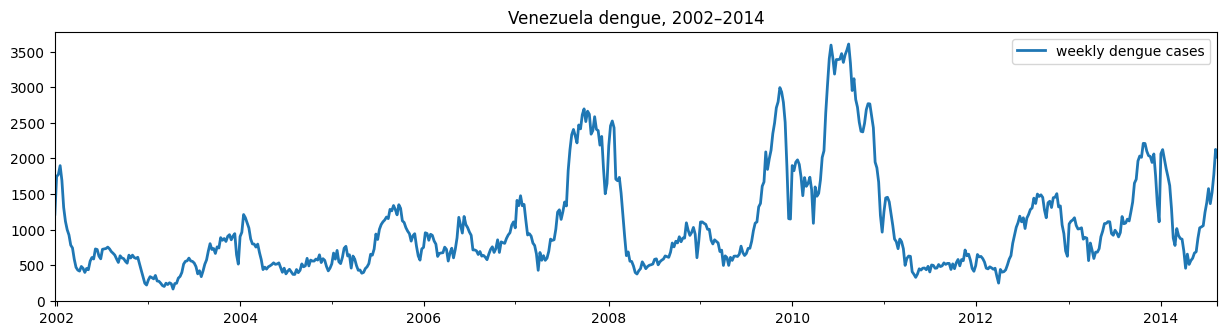

In [7]:
start = pd.to_datetime(f"{raw.Year.iloc[0]}-W{raw.Week.iloc[0]:02d}-1", format="%G-W%V-%u")
df = raw.assign(date=pd.date_range(start, periods=len(raw), freq=CFG["FREQ"]))
series = TimeSeries.from_dataframe(df, time_col="date", value_cols="Cases", freq=CFG["FREQ"]).astype(np.float32)
print("TimeSeries values shape (time, components, samples):", series.all_values().shape)

fig, ax = plt.subplots(figsize=(15, 3.5))
series.plot(ax=ax, label="weekly dengue cases"); ax.set_title("Venezuela dengue, 2002–2014"); ax.set_xlabel(""); plt.show()

In [8]:
print(series)
print("Values shape (time, components, samples):", series.all_values().shape)
print("Frequency:", series.freq_str, "| start:", series.start_time().date(), "| end:", series.end_time().date())

             Cases
date              
2001-12-31  1215.0
2002-01-07  1744.0
2002-01-14  1774.0
2002-01-21  1898.0
2002-01-28  1689.0
...            ...
2014-07-21  1364.0
2014-07-28  1520.0
2014-08-04  1770.0
2014-08-11  2126.0
2014-08-18  2020.0

shape: (660, 1, 1), freq: W-MON, size: 2.58 KB
Values shape (time, components, samples): (660, 1, 1)
Frequency: W-MON | start: 2001-12-31 | end: 2014-08-18


## Part 4 - Train, Validation, Test Split

We follow the same temporal split per horizon as the paper:

| Horizon | Train | Validation | Test |
|---------|-------|------------|------|
| 4 weeks | 647 weeks (to 19 May 2014) | 9 weeks (26 May – 21 Jul 2014) | 4 weeks (28 Jul – 18 Aug 2014) |
| 9 weeks | 638 weeks | 13 weeks (24 Mar – 16 Jun 2014) | 9 weeks (23 Jun – 18 Aug 2014) |
| 13 weeks | 621 weeks | 26 weeks (25 Nov 2013 – 19 May 2014) | 13 weeks (26 May – 18 Aug 2014) |

1. **Test** = the last **H** weeks of the series. Each horizon has its own test window.
2. **Validation** = the **V** weeks immediately before the test window. Used **only** to score Optuna trials.
3. **Train** = everything before that.
4. **Tuning (Part 7):** the scaler is fitted on **train**; each trial's model is trained on **train** and forecasts every rolling origin inside the validation window (V − H + 1 origins: 6, 5, 14). The validation weeks act as *inputs* for later origins but are never trained on.
5. **Final model (Part 8):** retrain on **train + validation** with the best settings (scaler refitted on train + validation), forecast the test window **once** from the last pre-test week; all H steps come from one forward pass.

Each horizon is a separate experiment: the H = 4 training data contain weeks that are test weeks for H = 13, which is fine because nothing is shared between horizons (separate studies, separate models).

,H (test weeks),V (validation weeks),train weeks,train period,validation period,test period,training windows (tuning),training windows (final),validation origins
short,4,9,647,2001-12-31 → 2014-05-19,2014-05-26 → 2014-07-21,2014-07-28 → 2014-08-18,592,601,6
medium,9,13,638,2001-12-31 → 2014-03-17,2014-03-24 → 2014-06-16,2014-06-23 → 2014-08-18,578,591,5
long,13,26,621,2001-12-31 → 2013-11-18,2013-11-25 → 2014-05-19,2014-05-26 → 2014-08-18,557,583,14


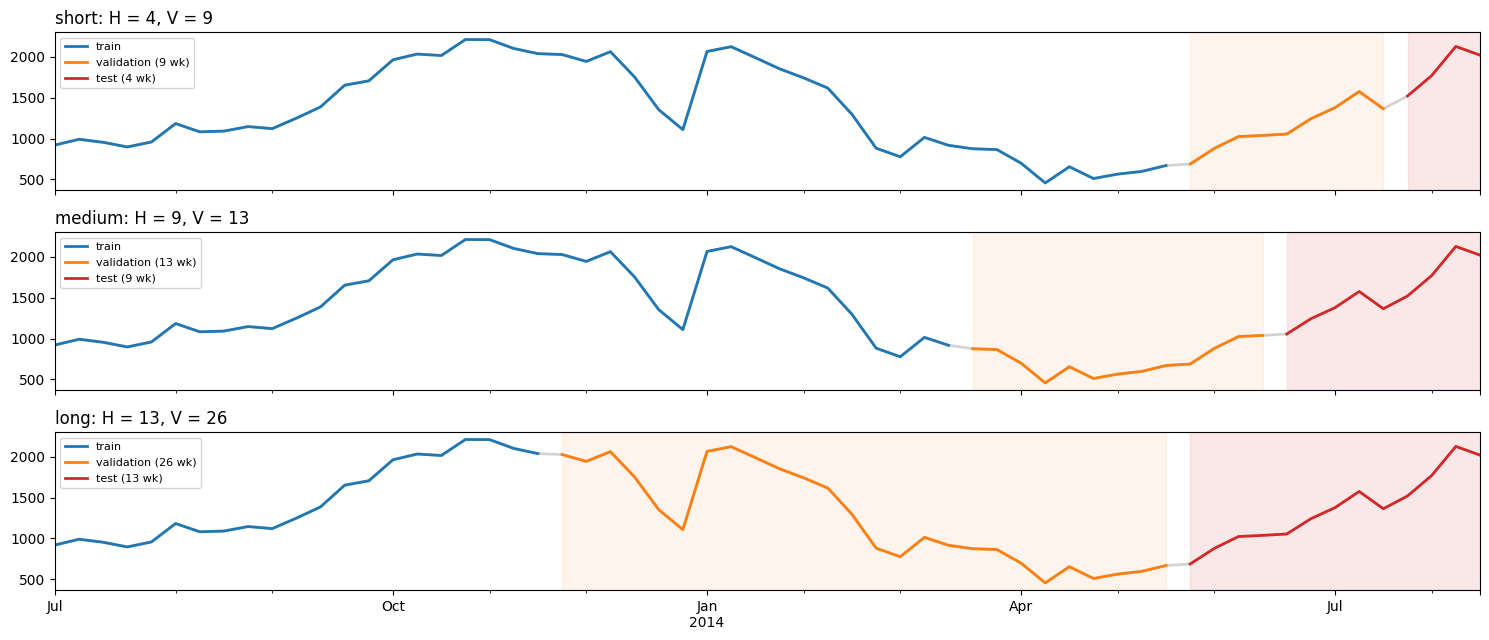

In [9]:
P = CFG["LOOKBACK"]
SPLITS = {}
for hname, hv in CFG["HORIZONS"].items():
    H, V = hv["H"], hv["V"]
    n_train = len(series) - H - V #training set length is whatever is left after removing the last H weeks (test) and the V weeks before them (validation)
    sp = dict(H=H, V=V, 
              n_train=n_train,
              train=series[:n_train],             # weeks 0 … 620
              val=series[n_train:n_train + V],    # weeks 621 … 646  (26 weeks)
              train_val=series[:n_train + V],     # weeks 0 … 646  (used for the final model)
              test=series[-H:])                   # weeks 647 … 659 (last 13 weeks)
    sp["n_train_windows"] = n_train - P - H + 1               # windows used to fit during tuning
    sp["n_final_windows"] = n_train + V - P - H + 1           # windows used to fit the final model
    sp["n_val_origins"] = V - H + 1                           # forecasts the trained model makes during validation
    SPLITS[hname] = sp

split_table = pd.DataFrame({h: {
    "H (test weeks)": s["H"], "V (validation weeks)": s["V"], "train weeks": s["n_train"],
    "train period": f"{s['train'].start_time().date()} → {s['train'].end_time().date()}",
    "validation period": f"{s['val'].start_time().date()} → {s['val'].end_time().date()}",
    "test period": f"{s['test'].start_time().date()} → {s['test'].end_time().date()}",
    "training windows (tuning)": s["n_train_windows"], "training windows (final)": s["n_final_windows"],
    "validation origins": s["n_val_origins"]} for h, s in SPLITS.items()}).T
display(split_table)

# Picture of the last 60 weeks for each horizon
fig, axes = plt.subplots(3, 1, figsize=(15, 6.5), sharex=True)
tail = series[-60:]
for ax, (hname, s) in zip(axes, SPLITS.items()):
    tail.plot(ax=ax, color="lightgray", label="_")
    s["train"].slice_intersect(tail).plot(ax=ax, label="train", color="tab:blue")
    s["val"].plot(ax=ax, label=f"validation ({s['V']} wk)", color="tab:orange")
    s["test"].plot(ax=ax, label=f"test ({s['H']} wk)", color="tab:red")
    ax.axvspan(s["val"].start_time(), s["val"].end_time(), color="tab:orange", alpha=0.08)
    ax.axvspan(s["test"].start_time(), s["test"].end_time(), color="tab:red", alpha=0.10)
    ax.set_title(f"{hname}: H = {s['H']}, V = {s['V']}", loc="left"); ax.set_xlabel(""); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()

In [10]:
# Leakage checks: the test window is disjoint from, and strictly after, everything used for fitting or tuning
for hname, sp in SPLITS.items():
    test_start = len(series) - sp["H"]
    assert sp["n_train"] + sp["V"] == test_start, hname
    assert len(sp["train_val"]) == test_start and len(sp["test"]) == sp["H"], hname
    assert sp["train"].end_time() < sp["val"].start_time() <= sp["val"].end_time() < sp["test"].start_time(), hname
    assert sp["train_val"].end_time() < sp["test"].start_time(), hname
    assert sp["n_val_origins"] >= 1, hname
print("OK  train < validation < test for every horizon; train_val ends the week before the test window")

OK  train < validation < test for every horizon; train_val ends the week before the test window


## Part 6 — Shared helpers

* `build_model` creates the EnTransformer engression model from a parameter dict (architecture, `lr`, noise).
* `fit_package_es` trains a model and first **asserts that the loss the package will call is the package's own `energy_score_loss`**, so no other estimator can slip in (Part 4b temporarily wraps it and restores it).
* `sample_forecast` returns samples in case units, shape `(H, 1, S)`, clipped at 0 **after** inverse scaling.
* `score` computes all metrics with `engressionts.metrics` (median point forecast, α = 0.05).

In [11]:
def trainer_kwargs():
    return dict(accelerator=ACCELERATOR, devices=1, enable_progress_bar=False,
                enable_model_summary=False, logger=False)

def build_model(kind, H, params, seed, n_epochs=None):
    if kind != "engression":
        raise ValueError(kind)
    return EnTransformerModel(input_chunk_length=P, output_chunk_length=H,
                              d_model=int(params["d_model"]), nhead=int(params["nhead"]),
                              num_encoder_layers=int(params["num_encoder_layers"]),
                              num_decoder_layers=int(params["num_decoder_layers"]),
                              dim_feedforward=int(params["dim_feedforward"]), dropout=float(params["dropout"]),
                              n_epochs=n_epochs or CFG["N_EPOCHS"], batch_size=CFG["BATCH_SIZE"],
                              optimizer_kwargs={"lr": float(params["lr"])}, random_state=seed,
                              pl_trainer_kwargs=trainer_kwargs(),
                              noise_type=params["noise_type"], noise_std=float(params["noise_std"]),
                              num_samples=CFG["M_TRAIN"])

_PACKAGE_ES = eng_base.energy_score_loss               # engressionts' own estimator, captured at import time
assert CFG["ES_LOSS"] == "package"

def fit_package_es(model, series_sc):
    # Train with the engressionts package energy score (and nothing else)
    assert eng_base.energy_score_loss is _PACKAGE_ES, "energy_score_loss has been replaced; restart the kernel"
    model.fit(series_sc, verbose=False)
    return model

def sample_forecast(model, histories_sc, H, scaler, n_samples, seed):
    # histories_sc: one scaled TimeSeries or a list. Returns list of arrays (H, 1, S) in case units.
    single = isinstance(histories_sc, TimeSeries)
    preds = model.predict(n=H, series=histories_sc, num_samples=n_samples, random_state=seed)
    preds = [preds] if single else preds
    return [np.clip(scaler.inverse_transform(p).all_values(), 0, None) for p in preds]

def score(y_true_ts, samples, y_train_ts, alpha=CFG["ALPHA"]):
    y, yt = y_true_ts.values(), y_train_ts.values()
    point = dict(MAE=M.mae(y, samples, point_method="median"),
                 RMSE=M.rmse(y, samples, point_method="median"),
                 SMAPE=M.smape(y, samples, point_method="median"),
                 MASE=M.mase(y, samples, yt, point_method="median"),
                 RMSSE=M.rmsse(y, samples, yt, point_method="median"))
    if samples.shape[-1] == 1:                           # point forecast: CRPS reduces to MAE, no interval
        prob = dict(CRPS=point["MAE"], Coverage95=np.nan, Width95=np.nan, Winkler95=np.nan,
                    Pinball80=M.pinball_loss(y, samples, 0.8), Pinball95=M.pinball_loss(y, samples, 0.95))
    else:
        prob = dict(CRPS=M.crps(y, samples),
                    Coverage95=M.empirical_coverage(y, samples, alpha=alpha),
                    Width95=M.mpiw(samples, alpha=alpha),
                    Winkler95=M.winkler_score(y, samples, alpha=alpha),
                    Pinball80=M.pinball_loss(y, samples, 0.8), Pinball95=M.pinball_loss(y, samples, 0.95))
    return {k: float(np.asarray(v)) for k, v in {**point, **prob}.items()}

## Part 7 — Hyper-parameter tuning with Optuna for this horizon (validation CRPS)

This notebook tunes **only `HORIZON`**. Every trial:

1. draws a setting from `SEARCH_SPACE` (TPE sampler, seeded);
2. fits the transform (log1p if chosen, then standardise) on **train only**;
3. for each seed in `TUNE_SEEDS`: trains EnTransformer on **train** with the package energy score, then forecasts H weeks from **every rolling origin in the validation window**: origin k uses train + the first k validation weeks as input (no retraining) and is scored on validation weeks k … k + H − 1, with `TUNE_N_PRED_SAMPLES` trajectories;
4. returns the **mean CRPS** (case units) over origins and seeds; Optuna minimises it.

Rolling origins give 6 / 5 / 14 forecasts per seed (H = 4 / 9 / 13). With `PRUNE=True` a trial is stopped after its 1st or 2nd seed if its running mean is worse than the median of earlier trials at the same point (median pruner, after 10 complete trials). Validation 95% coverage and interval width are stored with every trial, but **only CRPS drives the choice**. Trial 0 is the untuned default.

**Progress.** Every finished trial prints one line: state, its CRPS, best so far, trials done, seconds taken.

**Output.** `OUT_DIR` (`entransformer_tuning_<horizon>/`) receives `optuna_<horizon>.db` (the study, needed by the final notebook), `best_params_<horizon>.json`, `optuna_trials_<horizon>.csv`, `tuning_summary_<horizon>.csv` and the search-history figure. The study also stores the settings it was run with (`tuning_fingerprint`), so the final notebook can check that all three horizons were tuned the same way.

**Resuming.** If a run stops early, put its `optuna_<horizon>.db` back into `OUT_DIR` and run again: it continues from the last finished trial. To carry over trials from an older EnTransformer database instead, set `PREVIOUS_DB` to its path.

**Run time.** EnTransformer is much slower than EnBlockRNN. Measured on a 2-core CPU (H = 4, 100 epochs, one fit): smallest models ≈ 40 s, package default (trial 0) ≈ 6 min, largest in the search space (128 × 3 + 3 layers, 512 feed-forward) ≈ 14 min. With 100 trials × up to 3 seeds that is far more than one Kaggle session on CPU, so **use a GPU accelerator** (the notebook picks it up automatically). If a session still ends early, resume from the saved `.db` as described above.

In [12]:
import shutil

def suggest_params(trial):
    S = SEARCH_SPACE
    p = dict(d_model=trial.suggest_categorical("d_model", S["d_model"]),
             nhead=trial.suggest_categorical("nhead", S["nhead"]),
             num_encoder_layers=trial.suggest_int("num_encoder_layers", *S["num_encoder_layers"]),
             num_decoder_layers=trial.suggest_int("num_decoder_layers", *S["num_decoder_layers"]),
             dim_feedforward=trial.suggest_int("dim_feedforward", *S["dim_feedforward"], log=True),
             dropout=trial.suggest_float("dropout", *S["dropout"]),
             lr=trial.suggest_float("lr", *S["lr"], log=True),
             noise_type=trial.suggest_categorical("noise_type", S["noise_type"]),
             noise_std=trial.suggest_float("noise_std", *S["noise_std"], log=True),
             log_transform=trial.suggest_categorical("log_transform", S["log_transform"]))
    return p

def params_from_trial(t):
    # Full parameter dict from a finished trial (every setting is sampled, so this is just a copy)
    return dict(t.params)

def validation_setup(sp, log_transform):
    # Transform fitted on TRAIN only; one scaled history + one target per rolling validation origin
    scaler = make_scaler(log_transform)
    train_sc = scaler.fit_transform(sp["train"])
    n0, H = sp["n_train"], sp["H"]
    histories = [scaler.transform(series[:n0 + k]) for k in range(sp["n_val_origins"])]
    targets = [sp["val"][k:k + H] for k in range(sp["n_val_origins"])]
    # leakage guard: every input and every target lies before the test window
    assert all(len(h) <= n0 + sp["V"] - H for h in histories)
    assert all(t.end_time() <= sp["val"].end_time() < sp["test"].start_time() for t in targets)
    return scaler, train_sc, histories, targets

def validation_scores(sp, params, seeds, trial=None):
    # Mean validation CRPS over rolling origins and seeds (case units); prunes the trial if asked
    scaler, train_sc, histories, targets = validation_setup(sp, params["log_transform"])
    crps, cov, width = [], [], []
    for i, seed in enumerate(seeds):
        model = fit_package_es(build_model("engression", sp["H"], params, seed), train_sc)
        smps = sample_forecast(model, histories, sp["H"], scaler, CFG["TUNE_N_PRED_SAMPLES"], seed)
        crps.append(np.mean([float(np.asarray(M.crps(t.values(), s))) for t, s in zip(targets, smps)]))
        cov.append(np.mean([float(np.asarray(M.empirical_coverage(t.values(), s, alpha=CFG["ALPHA"]))) for t, s in zip(targets, smps)]))
        width.append(np.mean([float(np.asarray(M.mpiw(s, alpha=CFG["ALPHA"]))) for s in smps]))
        if trial is not None:
            trial.report(float(np.mean(crps)), i)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return dict(crps=float(np.mean(crps)), crps_sd_seeds=float(np.std(crps)),
                coverage95=float(np.mean(cov)), width95=float(np.mean(width)), crps_per_seed=[float(c) for c in crps])

def progress(study, trial):
    # One line per finished trial, so a long run shows it is alive
    done = [t for t in study.trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)]
    complete = [t for t in done if t.state == TrialState.COMPLETE]
    val = f"{trial.value:.1f}" if trial.value is not None else "-"
    best = f"{min(t.value for t in complete):.1f}" if complete else "-"
    secs = (trial.datetime_complete - trial.datetime_start).total_seconds() if trial.datetime_complete else float("nan")
    print(f"  {study.study_name}: trial {trial.number:3d} {trial.state.name:8s} CRPS {val:>7s} | best {best:>7s} | "
          f"{len(done)}/{CFG['N_TRIALS']} done | {secs:.0f}s", flush=True)

def make_objective(sp):
    def objective(trial):
        params = suggest_params(trial)
        res = validation_scores(sp, params, CFG["TUNE_SEEDS"], trial)
        for k in ("crps_sd_seeds", "coverage95", "width95", "crps_per_seed"):
            trial.set_user_attr(k, res[k])
        return res["crps"]
    return objective

hname, sp = HORIZON, SPLITS[HORIZON]
STUDY_NAME = f"entransformer_{hname}_H{sp['H']}"

# Optional: carry over this horizon's trials from an older database (input folders are read-only, so copy first)
if CFG["PREVIOUS_DB"] and STUDY_NAME not in optuna.study.get_all_study_names(CFG["OPTUNA_STORAGE"]):
    tmp = f"{CFG['OUT_DIR']}/_previous_copy.db"
    shutil.copy(CFG["PREVIOUS_DB"], tmp)
    if STUDY_NAME in optuna.study.get_all_study_names(f"sqlite:///{tmp}"):
        optuna.copy_study(from_study_name=STUDY_NAME, from_storage=f"sqlite:///{tmp}", to_storage=CFG["OPTUNA_STORAGE"])
        print(f"Carried over {STUDY_NAME} from {CFG['PREVIOUS_DB']}")
    else:
        print(f"{STUDY_NAME} not found in {CFG['PREVIOUS_DB']}; starting a new study")
    os.remove(tmp)

study = optuna.create_study(
    study_name=STUDY_NAME, direction="minimize", storage=CFG["OPTUNA_STORAGE"], load_if_exists=True,
    sampler=TPESampler(seed=CFG["OPTUNA_SEED"], multivariate=True),
    pruner=MedianPruner(n_startup_trials=10, n_warmup_steps=0) if CFG["PRUNE"] else NopPruner())

# Record (or check) the settings this study is run with; the final notebook compares them across horizons
fp = tuning_fingerprint(hname)
stored = study.user_attrs.get("tuning_fingerprint")
if stored is None:
    study.set_user_attr("tuning_fingerprint", fp)
elif stored != fp:
    diff = sorted(k for k in set(fp) | set(stored) if fp.get(k) != stored.get(k))
    raise ValueError(f"{CFG['OPTUNA_STORAGE']} holds a study run with different settings: {diff}. "
                     "Change OUT_DIR or delete the file to start fresh.")

if len(study.trials) == 0:
    study.enqueue_trial(dict(DEFAULT_PARAMS))   # trial 0 = untuned default
finished = [t for t in study.trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)]
remaining = max(0, CFG["N_TRIALS"] - len(finished))
print(f"{STUDY_NAME}: {len(finished)} trials already finished, running {remaining} more")
t0 = time.time()
study.optimize(make_objective(sp), n_trials=remaining, gc_after_trial=True, callbacks=[progress],
               catch=(RuntimeError, ValueError))   # a diverging trial is marked FAIL; the study continues

n_c = sum(t.state == TrialState.COMPLETE for t in study.trials)
n_p = sum(t.state == TrialState.PRUNED for t in study.trials)
STUDIES = {hname: study}
BEST = {hname: params_from_trial(study.best_trial)}
print(f"{hname} H={sp['H']}: {n_c} complete, {n_p} pruned, {(time.time() - t0) / 60:.1f} min this run | "
      f"best val CRPS {study.best_value:.1f} (trial {study.best_trial.number})")

entransformer_long_H13: 0 trials already finished, running 100 more
  entransformer_long_H13: trial   0 COMPLETE CRPS   442.2 | best   442.2 | 1/100 done | 123s
  entransformer_long_H13: trial   1 COMPLETE CRPS   589.5 | best   442.2 | 2/100 done | 109s
  entransformer_long_H13: trial   2 COMPLETE CRPS   460.9 | best   442.2 | 3/100 done | 79s
  entransformer_long_H13: trial   3 COMPLETE CRPS   541.9 | best   442.2 | 4/100 done | 79s
  entransformer_long_H13: trial   4 COMPLETE CRPS  1003.0 | best   442.2 | 5/100 done | 100s
  entransformer_long_H13: trial   5 COMPLETE CRPS   917.0 | best   442.2 | 6/100 done | 97s
  entransformer_long_H13: trial   6 COMPLETE CRPS   687.8 | best   442.2 | 7/100 done | 58s
  entransformer_long_H13: trial   7 COMPLETE CRPS   666.6 | best   442.2 | 8/100 done | 78s
  entransformer_long_H13: trial   8 COMPLETE CRPS  1914.8 | best   442.2 | 9/100 done | 78s
  entransformer_long_H13: trial   9 COMPLETE CRPS   564.7 | best   442.2 | 10/100 done | 79s
  entran

### Tuning results

The table compares the **best trial** with **trial 0 (the untuned defaults)** on the validation window. Both are means over the same 3 seeds and all rolling origins. The figures show the search history (each dot is a finished trial; the line is the best so far) and which settings mattered most.

Validation results: untuned defaults vs. best Optuna trial (CRPS in cases/week, lower is better)


H  number  val CRPS  sd over seeds  \
horizon trial                                                    
long    untuned (trial 0)  13       0  442.1619        28.7273   
        best               13      76  270.3665         4.7574   

                           val coverage95  val width95  d_model  nhead  \
horizon trial                                                            
long    untuned (trial 0)          0.6410    1353.7221       64      4   
        best                       0.9304    2012.7472      128      2   

                           num_encoder_layers  num_decoder_layers  \
horizon trial                                                       
long    untuned (trial 0)                   3                   3   
        best                                2                   2   

                           dim_feedforward  dropout     lr noise_type  \
horizon trial                                                           
long    untuned (trial 0)              512    0.100  0.001   gaussian   
        best                           169    0.002  0.000   gaussian   

                           noise_std  log_transform  
horizon trial                                        
long    untuned (trial 0)     1.0000           True  
        best                  1.6169          False

Best hyper-parameters per horizon (used for the final model):


,d_model,nhead,num_encoder_layers,num_decoder_layers,dim_feedforward,dropout,lr,noise_type,noise_std,log_transform
long,128,2,2,2,169,0.001994,0.000023,gaussian,1.616906,False


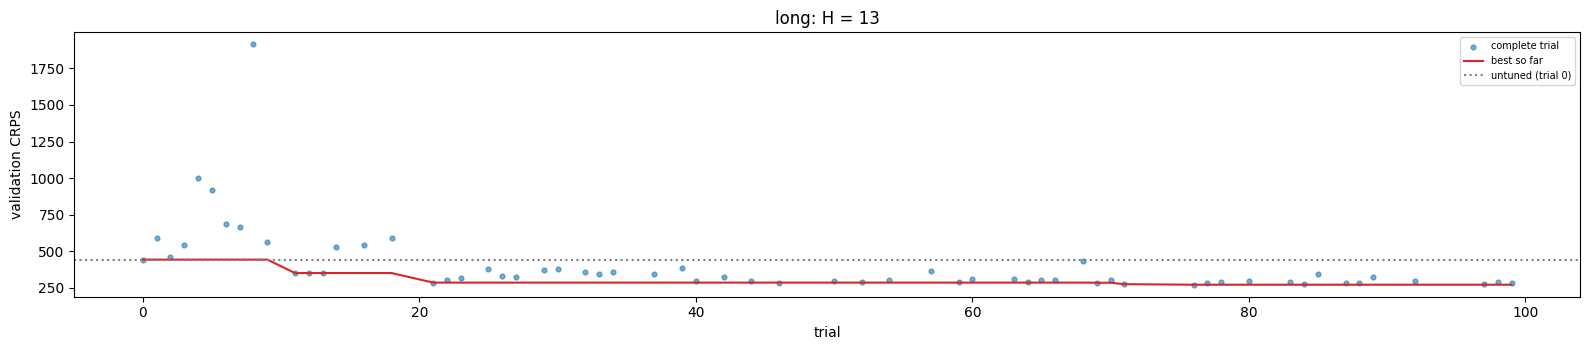

Hyper-parameter importance (fANOVA, share of validation-CRPS variance explained):


,long
dropout,0.319
lr,0.226
dim_feedforward,0.192
noise_std,0.117
d_model,0.050
num_decoder_layers,0.039
num_encoder_layers,0.039
nhead,0.010
noise_type,0.005
log_transform,0.003


In [13]:
rows = []
for hname, study in STUDIES.items():
    t0_ = next(t for t in study.trials if t.number == 0)
    bt = study.best_trial
    for label, t in [("untuned (trial 0)", t0_), ("best", bt)]:
        rows.append({"horizon": hname, "H": SPLITS[hname]["H"], "trial": label, "number": t.number,
                     "val CRPS": t.value, "sd over seeds": t.user_attrs.get("crps_sd_seeds"),
                     "val coverage95": t.user_attrs.get("coverage95"), "val width95": t.user_attrs.get("width95"),
                     **params_from_trial(t)})
tuning_summary = pd.DataFrame(rows).set_index(["horizon", "trial"])
print("Validation results: untuned defaults vs. best Optuna trial (CRPS in cases/week, lower is better)")
display(tuning_summary.round(4))

print("Best hyper-parameters per horizon (used for the final model):")
display(pd.DataFrame(BEST).T)

fig, axes = plt.subplots(1, len(STUDIES), figsize=(16, 3.6))
for ax, (hname, study) in zip(np.atleast_1d(axes), STUDIES.items()):
    done = [t for t in study.trials if t.state == TrialState.COMPLETE]
    x = [t.number for t in done]; y = [t.value for t in done]
    ax.scatter(x, y, s=12, alpha=0.6, label="complete trial")
    ax.plot(x, np.minimum.accumulate(y), color="tab:red", lw=1.5, label="best so far")
    ax.axhline(next(t for t in study.trials if t.number == 0).value, color="gray", ls=":", label="untuned (trial 0)")
    ax.set_title(f"{hname}: H = {SPLITS[hname]['H']}"); ax.set_xlabel("trial"); ax.set_ylabel("validation CRPS")
np.atleast_1d(axes)[0].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{CFG['OUT_DIR']}/fig_optuna_history.png", dpi=150); plt.show()

imp_rows = {}
for hname, study in STUDIES.items():
    try:
        imp_rows[hname] = optuna.importance.get_param_importances(study)
    except Exception as e:                                # needs enough complete trials
        print(f"{hname}: importances not available ({e.__class__.__name__}: {e})")
if imp_rows:
    print("Hyper-parameter importance (fANOVA, share of validation-CRPS variance explained):")
    display(pd.DataFrame(imp_rows).round(3))

## Part 8 — Save the study and best settings

In [14]:
out = CFG["OUT_DIR"]
tuning_summary.to_csv(f"{out}/tuning_summary_{HORIZON}.csv")
study.trials_dataframe().to_csv(f"{out}/optuna_trials_{HORIZON}.csv", index=False)
with open(f"{out}/best_params_{HORIZON}.json", "w") as fh:
    json.dump(dict(horizon=HORIZON, study_name=STUDY_NAME, best_value=study.best_value,
                   best_trial=study.best_trial.number, best_params=BEST[HORIZON],
                   fingerprint=tuning_fingerprint(HORIZON), versions=VERSIONS, accelerator=ACCELERATOR),
              fh, indent=2, default=str)
os.replace(f"{out}/fig_optuna_history.png", f"{out}/fig_optuna_history_{HORIZON}.png")
print(sorted(os.listdir(out)))
print(f"\nNext: attach this notebook's output ({out}/optuna_{HORIZON}.db) to entransformer-final.ipynb.")

['best_params_long.json', 'fig_optuna_history_long.png', 'optuna_long.db', 'optuna_trials_long.csv', 'tuning_summary_long.csv']

Next: attach this notebook's output (entransformer_tuning_long/optuna_long.db) to entransformer-final.ipynb.
